<a href="https://colab.research.google.com/github/mdnazishpatel/Machine_learning/blob/main/PyTorch_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###PyTorch Workflow

In [101]:
### PyTorch Workflow
what_iam_going_todo = {
     1: "data (prepare and load)",
     2: "build model",
     3: "fitting the model to data (training)",
     4: "making predictions and evaluating a model (inference)",
     5: "putting it all together"
 }
what_iam_going_todo

{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data (training)',
 4: 'making predictions and evaluating a model (inference)',
 5: 'putting it all together'}

In [102]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

'2.14.1+cpu'

## Data preparing -  `(data can be anything and converting any data into numerical type)`

In [103]:
## Lenear Regression formula

weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [104]:
len(X), len(y)

(50, 50)

In [105]:
## Creating a train/test split
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

Visulaizing our data through matplotlib

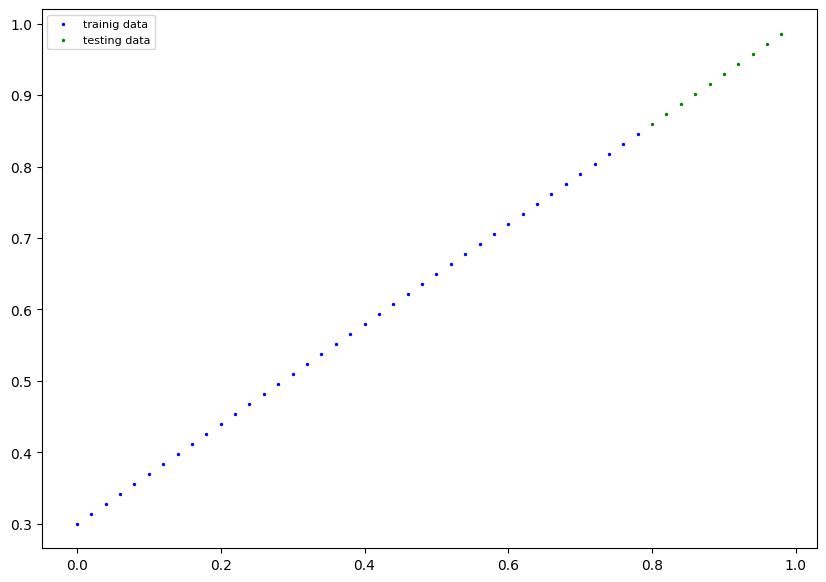

In [106]:
from prompt_toolkit.shortcuts.progress_bar import Label
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  """
  plots training data,test data and compares predictions
  """
  plt.figure(figsize=(10,7))
  #plot tarining data in blue
  plt.scatter(train_data, train_labels, c="b", s=2, label="trainig data")

  #plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=2, label="testing data")

  # predicitons
  if predictions is not None:
   plt.scatter(test_data, predictions, c="r", s=2, label="predictions")

  plt.legend(prop={"size": 8})
plot_predictions()

## BUILDIND MODEL - Lenear regression

In [107]:
class LinearRegressionModel(nn.Module): #-> alomst everything in pytorch is inherited by nn.modeule
  def __init__(self):
    super().__init__()
    #Initilize model parameter
    self.weights = nn.Parameter(torch.randn(1,
                                            requires_grad=True,
                                            dtype=torch.float))
    self.bias = nn.Parameter(torch.randn(1,
                                         requires_grad=True,
                                         dtype=torch.float))
    #forward() defines the computation in the model
  def forward(self, X:torch.Tensor) -> torch.Tensor:
      return self.weights * X + self.bias ##Linear regression formula



In [108]:
torch.manual_seed(42)
model_0 = LinearRegressionModel()
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [109]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [110]:
weight , bias

(0.7, 0.3)

In [111]:
## Making predictions using toch.inference_module()
## inference mode does not track gradient that's why we use it
with torch.inference_mode():
  y_preds = model_0(X_test)

y_preds


tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

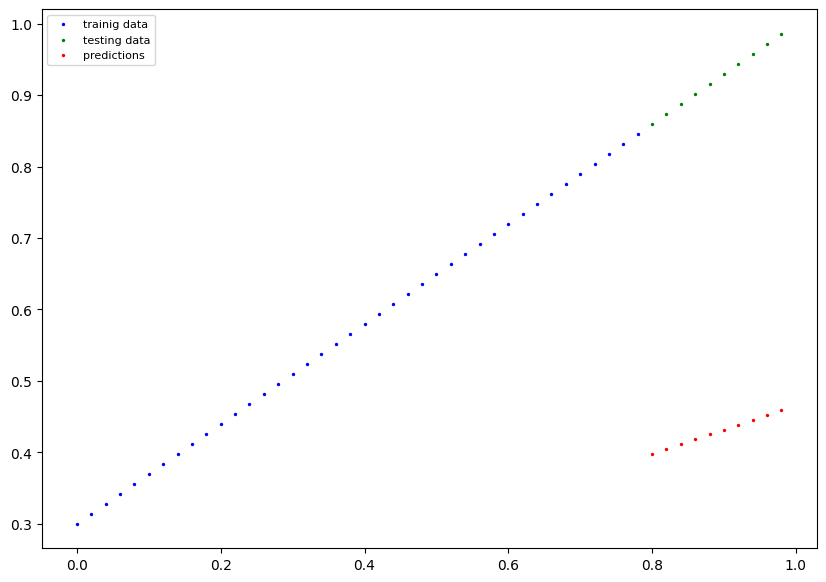

In [112]:
plot_predictions(predictions=y_preds)

 ### Training a model.
  so the whole idea of training a model is move unkown parameters to known parameters basically better representation of data
  So we use loss function for it

  **Loss function** : a function that measures how wrong the predictions is to the ideal output
  
  **Optimizer** : Takes account the loss of a model ad adjust the parameters (weights, bias)

In [113]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.01)

In [114]:

import numpy as np
epoches = 200  # one loop through data
epoch_count = []
loss_count = []
test_loss_value = []

for epoch in range(epoches):

  # setting the model into training mode
  model_0.train()
  # Forawrdpass()
  y_preds = model_0(X_train)
  # Calculate loss
  loss = loss_fn(y_preds, y_train)

  # Optimizer zero grad
  optimizer.zero_grad()
  # perform backpropagatation on the loss
  loss.backward()
  # perform gardient descent
  optimizer.step()
  model_0.eval()

  with torch.inference_mode():
     test_predict = model_0(X_test)
     test_loss = loss_fn(test_predict, y_test)


  if epoch % 10 == 0:
    epoch_count.append(epoch)
    loss_count.append(loss.item())
    test_loss_value.append(test_loss.item())
    print(f"Epoch: {epoch} | Loss: {loss} | Test loss: {test_loss}")

    print(model_0.state_dict())

Epoch: 0 | Loss: 0.31288138031959534 | Test loss: 0.48106518387794495
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388])})
Epoch: 10 | Loss: 0.1976713240146637 | Test loss: 0.3463551998138428
OrderedDict({'weights': tensor([0.3796]), 'bias': tensor([0.2388])})
Epoch: 20 | Loss: 0.08908725529909134 | Test loss: 0.21729660034179688
OrderedDict({'weights': tensor([0.4184]), 'bias': tensor([0.3333])})
Epoch: 30 | Loss: 0.053148526698350906 | Test loss: 0.14464017748832703
OrderedDict({'weights': tensor([0.4512]), 'bias': tensor([0.3768])})
Epoch: 40 | Loss: 0.04543796554207802 | Test loss: 0.11360953003168106
OrderedDict({'weights': tensor([0.4748]), 'bias': tensor([0.3868])})
Epoch: 50 | Loss: 0.04167863354086876 | Test loss: 0.09919948130846024
OrderedDict({'weights': tensor([0.4938]), 'bias': tensor([0.3843])})
Epoch: 60 | Loss: 0.03818932920694351 | Test loss: 0.08886633068323135
OrderedDict({'weights': tensor([0.5116]), 'bias': tensor([0.3788])})
Epoch: 70 | Loss: 0.03

In [115]:
import numpy as np
np.array(torch.tensor(loss_count).numpy()), test_loss_value

(array([0.31288138, 0.19767132, 0.08908726, 0.05314853, 0.04543797,
        0.04167863, 0.03818933, 0.0347609 , 0.03132383, 0.0278874 ,
        0.02445896, 0.02102021, 0.01758547, 0.01415539, 0.01071659,
        0.00728353, 0.00385178, 0.00893248, 0.00893248, 0.00893248],
       dtype=float32),
 [0.48106518387794495,
  0.3463551998138428,
  0.21729660034179688,
  0.14464017748832703,
  0.11360953003168106,
  0.09919948130846024,
  0.08886633068323135,
  0.0805937647819519,
  0.07232122868299484,
  0.06473556160926819,
  0.05646304413676262,
  0.04819049686193466,
  0.04060482233762741,
  0.03233227878808975,
  0.024059748277068138,
  0.016474086791276932,
  0.008201557211577892,
  0.005023092031478882,
  0.005023092031478882,
  0.005023092031478882])

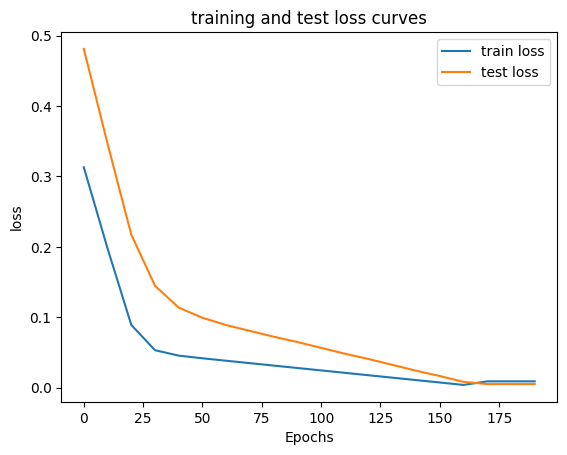

In [116]:
plt.plot(epoch_count, np.array(torch.tensor(loss_count).numpy()), label="train loss")
plt.plot(epoch_count, test_loss_value, label="test loss")
plt.title("training and test loss curves")
plt.ylabel("loss")
plt.xlabel("Epochs")
plt.legend()


In [120]:
with torch.inference_mode():

  y_preds_new = model_0(X_test)

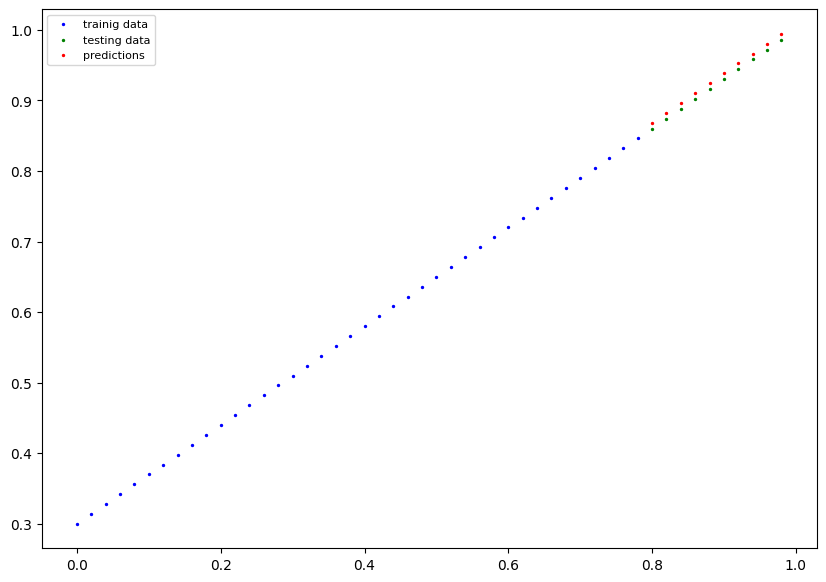

In [121]:
plot_predictions(predictions=y_preds_new)

In [122]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.6990])), ('bias', tensor([0.3093]))])